<a href="https://colab.research.google.com/github/Rajat504/CLOUDYML/blob/main/University_schema_with_Answers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><u><center>University Schema Assignment</center></u></h1>

### **DATABASE CREATION AND CONNECTING IT**


In [ ]:
import pandas as pd
import sqlite3
connection=sqlite3.connect('university.db')

In [ ]:
%load_ext sql
%sql sqlite:///university.db

### NOW WE WILL CREATE TABLES AND INSERT DATA


In [ ]:
%%sql
create table classroom
	(building		varchar(15),
	 room_number		varchar(7),
	 capacity		numeric(4,0),
	 primary key (building, room_number)
	);


In [ ]:
%%sql
insert into classroom values ('Packard', '101', '500');
insert into classroom values ('Painter', '514', '10');
insert into classroom values ('Taylor', '3128', '70');
insert into classroom values ('Watson', '100', '30');
insert into classroom values ('Watson', '120', '50');
insert into classroom values ('Taylor', '112', '30');
insert into classroom values ('Painter', '234', '50');
insert into classroom values ('Packard', '303', '56')

In [ ]:
%%sql
select * from classroom

In [ ]:
%%sql
create table department
	(dept_name		varchar(20),
	 building		varchar(15),
	 budget		        numeric(12,2) check (budget > 0),
	 primary key (dept_name)
	);

In [ ]:
%%sql
insert into department values ('Biology', 'Watson', '90000');
insert into department values ('Comp. Sci.', 'Taylor', '100000');
insert into department values ('Elec. Eng.', 'Taylor', '85000');
insert into department values ('Finance', 'Painter', '120000');
insert into department values ('History', 'Painter', '50000');
insert into department values ('Music', 'Packard', '80000');
insert into department values ('Physics', 'Watson', '70000');

In [ ]:
%%sql
select * from department

In [ ]:
%%sql
create table course
	(course_id		varchar(8),
	 title			varchar(50),
	 dept_name		varchar(20),
	 credits		numeric(2,0) check (credits > 0),
	 primary key (course_id),
	 foreign key (dept_name) references department (dept_name)
		on delete set null
	);

In [ ]:
%%sql

insert into course values ('BIO-101', 'Intro. to Biology', 'Biology', '4');
insert into course values ('BIO-301', 'Genetics', 'Biology', '4');
insert into course values ('BIO-399', 'Computational Biology', 'Biology', '3');
insert into course values ('CS-101', 'Intro. to Computer Science', 'Comp. Sci.', '4');
insert into course values ('CS-190', 'Game Design', 'Comp. Sci.', '4');
insert into course values ('CS-315', 'Robotics', 'Comp. Sci.', '3');
insert into course values ('CS-319', 'Image Processing', 'Comp. Sci.', '3');
insert into course values ('CS-347', 'Database System Concepts', 'Comp. Sci.', '3');
insert into course values ('EE-181', 'Intro. to Digital Systems', 'Elec. Eng.', '3');
insert into course values ('FIN-201', 'Investment Banking', 'Finance', '3');
insert into course values ('HIS-351', 'World History', 'History', '3');
insert into course values ('MU-199', 'Music Video Production', 'Music', '3');
insert into course values ('PHY-101', 'Physical Principles', 'Physics', '4');

In [ ]:
%%sql
select * from course

In [ ]:
%%sql
create table instructor
	(ID			varchar(5),
	 name			varchar(20) not null,
	 dept_name		varchar(20),
	 salary			numeric(8,2) check (salary > 29000),
	 primary key (ID),
	 foreign key (dept_name) references department (dept_name)
		on delete set null
	);

In [ ]:
%%sql
insert into instructor values ('10101', 'Srinivasan', 'Comp. Sci.', '65000');
insert into instructor values ('12121', 'Wu', 'Finance', '90000');
insert into instructor values ('15151', 'Mozart', 'Music', '40000');
insert into instructor values ('22222', 'Einstein', 'Physics', '95000');
insert into instructor values ('32343', 'El Said', 'History', '60000');
insert into instructor values ('33456', 'Gold', 'Physics', '87000');
insert into instructor values ('45565', 'Katz', 'Comp. Sci.', '75000');
insert into instructor values ('58583', 'Califieri', 'History', '62000');
insert into instructor values ('76543', 'Singh', 'Finance', '80000');
insert into instructor values ('76766', 'Crick', 'Biology', '72000');
insert into instructor values ('83821', 'Brandt', 'Comp. Sci.', '92000');
insert into instructor values ('98345', 'Kim', 'Elec. Eng.', '80000');

In [ ]:
%%sql
select * from instructor

In [ ]:
%%sql
create table section
	(course_id		varchar(8),
         sec_id			varchar(8),
	 semester		varchar(6)
		check (semester in ('Fall', 'Winter', 'Spring', 'Summer')),
	 year			numeric(4,0) check (year > 1701 and year < 2100),
	 building		varchar(15),
	 room_number		varchar(7),
	 time_slot_id		varchar(4),
	 primary key (course_id, sec_id, semester, year),
	 foreign key (course_id) references course (course_id)
		on delete cascade,
	 foreign key (building, room_number) references classroom (building, room_number)
		on delete set null
	);



In [ ]:
%%sql
insert into section values ('BIO-101', '1', 'Summer', '2017', 'Painter', '514', 'B');
insert into section values ('BIO-301', '1', 'Summer', '2018', 'Painter', '514', 'A');
insert into section values ('CS-101', '1', 'Fall', '2017', 'Packard', '101', 'H');
insert into section values ('CS-101', '1', 'Spring', '2018', 'Packard', '101', 'F');
insert into section values ('CS-190', '1', 'Spring', '2017', 'Taylor', '3128', 'E');
insert into section values ('CS-190', '2', 'Spring', '2017', 'Taylor', '3128', 'A');
insert into section values ('CS-315', '1', 'Spring', '2018', 'Watson', '120', 'D');
insert into section values ('CS-319', '1', 'Spring', '2018', 'Watson', '100', 'B');
insert into section values ('CS-319', '2', 'Spring', '2018', 'Taylor', '3128', 'C');
insert into section values ('CS-347', '1', 'Fall', '2017', 'Taylor', '3128', 'A');
insert into section values ('EE-181', '1', 'Spring', '2017', 'Taylor', '3128', 'C');
insert into section values ('FIN-201', '1', 'Spring', '2018', 'Packard', '101', 'B');
insert into section values ('HIS-351', '1', 'Spring', '2018', 'Painter', '514', 'C');
insert into section values ('MU-199', '1', 'Spring', '2018', 'Packard', '101', 'D');
insert into section values ('PHY-101', '1', 'Fall', '2017', 'Watson', '100', 'A');

In [ ]:
%%sql
select * from section

In [ ]:
%%sql
create table teaches
	(ID			varchar(5),
	 course_id		varchar(8),
	 sec_id			varchar(8),
	 semester		varchar(6),
	 year			numeric(4,0),
	 primary key (ID, course_id, sec_id, semester, year),
	 foreign key (course_id, sec_id, semester, year) references section (course_id, sec_id, semester, year)
		on delete cascade,
	 foreign key (ID) references instructor (ID)
		on delete cascade
	);

In [ ]:
%%sql
insert into teaches values ('10101', 'CS-101', '1', 'Fall', '2017');
insert into teaches values ('10101', 'CS-315', '1', 'Spring', '2018');
insert into teaches values ('10101', 'CS-347', '1', 'Fall', '2017');
insert into teaches values ('12121', 'FIN-201', '1', 'Spring', '2018');
insert into teaches values ('15151', 'MU-199', '1', 'Spring', '2018');
insert into teaches values ('22222', 'PHY-101', '1', 'Fall', '2017');
insert into teaches values ('32343', 'HIS-351', '1', 'Spring', '2018');
insert into teaches values ('45565', 'CS-101', '1', 'Spring', '2018');
insert into teaches values ('45565', 'CS-319', '1', 'Spring', '2018');
insert into teaches values ('76766', 'BIO-101', '1', 'Summer', '2017');
insert into teaches values ('76766', 'BIO-301', '1', 'Summer', '2018');
insert into teaches values ('83821', 'CS-190', '1', 'Spring', '2017');
insert into teaches values ('83821', 'CS-190', '2', 'Spring', '2017');
insert into teaches values ('83821', 'CS-319', '2', 'Spring', '2018');
insert into teaches values ('98345', 'EE-181', '1', 'Spring', '2017');

In [ ]:
%%sql
select * from teaches

In [ ]:
%%sql
create table student
	(ID			varchar(5),
	 name			varchar(20) not null,
	 dept_name		varchar(20),
	 tot_cred		numeric(3,0) check (tot_cred >= 0),
	 primary key (ID),
	 foreign key (dept_name) references department (dept_name)
		on delete set null
	);



In [ ]:
%%sql

insert into student values ('00128', 'Zhang', 'Comp. Sci.', '102');
insert into student values ('12345', 'Shankar', 'Comp. Sci.', '32');
insert into student values ('19991', 'Brandt', 'History', '80');
insert into student values ('23121', 'Chavez', 'Finance', '110');
insert into student values ('44553', 'Peltier', 'Physics', '56');
insert into student values ('45678', 'Levy', 'Physics', '46');
insert into student values ('54321', 'Williams', 'Comp. Sci.', '54');
insert into student values ('55739', 'Sanchez', 'Music', '38');
insert into student values ('70557', 'Snow', 'Physics', '0');
insert into student values ('76543', 'Brown', 'Comp. Sci.', '58');
insert into student values ('76653', 'Aoi', 'Elec. Eng.', '60');
insert into student values ('98765', 'Bourikas', 'Elec. Eng.', '98');
insert into student values ('98988', 'Tanaka', 'Biology', '120');

In [ ]:
%%sql
select * from student

In [ ]:
%%sql
create table takes
	(ID			varchar(5),
	 course_id		varchar(8),
	 sec_id			varchar(8),
	 semester		varchar(6),
	 year			numeric(4,0),
	 grade		        varchar(2),
	 primary key (ID, course_id, sec_id, semester, year),
	 foreign key (course_id, sec_id, semester, year) references section (course_id, sec_id, semester, year)
		on delete cascade,
	 foreign key (ID) references student (ID)
		on delete cascade
	);



In [ ]:
%%sql
insert into takes values ('00128', 'CS-101', '1', 'Fall', '2017', 'A');
insert into takes values ('00128', 'CS-347', '1', 'Fall', '2017', 'A-');
insert into takes values ('12345', 'CS-101', '1', 'Fall', '2017', 'C');
insert into takes values ('12345', 'CS-190', '2', 'Spring', '2017', 'A');
insert into takes values ('12345', 'CS-315', '1', 'Spring', '2018', 'A');
insert into takes values ('12345', 'CS-347', '1', 'Fall', '2017', 'A');
insert into takes values ('19991', 'HIS-351', '1', 'Spring', '2018', 'B');
insert into takes values ('23121', 'FIN-201', '1', 'Spring', '2018', 'C+');
insert into takes values ('44553', 'PHY-101', '1', 'Fall', '2017', 'B-');
insert into takes values ('45678', 'CS-101', '1', 'Fall', '2017', 'F');
insert into takes values ('45678', 'CS-101', '1', 'Spring', '2018', 'B+');
insert into takes values ('45678', 'CS-319', '1', 'Spring', '2018', 'B');
insert into takes values ('54321', 'CS-101', '1', 'Fall', '2017', 'A-');
insert into takes values ('54321', 'CS-190', '2', 'Spring', '2017', 'B+');
insert into takes values ('55739', 'MU-199', '1', 'Spring', '2018', 'A-');
insert into takes values ('76543', 'CS-101', '1', 'Fall', '2017', 'A');
insert into takes values ('76543', 'CS-319', '2', 'Spring', '2018', 'A');
insert into takes values ('76653', 'EE-181', '1', 'Spring', '2017', 'C');
insert into takes values ('98765', 'CS-101', '1', 'Fall', '2017', 'C-');
insert into takes values ('98765', 'CS-315', '1', 'Spring', '2018', 'B');
insert into takes values ('98988', 'BIO-101', '1', 'Summer', '2017', 'A');
insert into takes values ('98988', 'BIO-301', '1', 'Summer', '2018', null);

In [ ]:
%%sql
select * from takes

In [ ]:
%%sql
create table advisor
	(s_ID			varchar(5),
	 i_ID			varchar(5),
	 primary key (s_ID),
	 foreign key (i_ID) references instructor (ID)
		on delete set null,
	 foreign key (s_ID) references student (ID)
		on delete cascade
	);



In [ ]:
%%sql
insert into advisor values ('00128', '45565');
insert into advisor values ('12345', '10101');
insert into advisor values ('23121', '76543');
insert into advisor values ('44553', '22222');
insert into advisor values ('45678', '22222');
insert into advisor values ('76543', '45565');
insert into advisor values ('76653', '98345');
insert into advisor values ('98765', '98345');
insert into advisor values ('98988', '76766');

In [ ]:
%%sql
select * from advisor

In [ ]:
%%sql
create table time_slot
	(time_slot_id		varchar(4),
	 day			varchar(1),
	 start_hr		numeric(2) check (start_hr >= 0 and start_hr < 24),
	 start_min		numeric(2) check (start_min >= 0 and start_min < 60),
	 end_hr			numeric(2) check (end_hr >= 0 and end_hr < 24),
	 end_min		numeric(2) check (end_min >= 0 and end_min < 60),
	 primary key (time_slot_id, day, start_hr, start_min)
	);



In [ ]:
%%sql
insert into time_slot values ('A', 'M', '8', '0', '8', '50');
insert into time_slot values ('A', 'W', '8', '0', '8', '50');
insert into time_slot values ('A', 'F', '8', '0', '8', '50');
insert into time_slot values ('B', 'M', '9', '0', '9', '50');
insert into time_slot values ('B', 'W', '9', '0', '9', '50');
insert into time_slot values ('B', 'F', '9', '0', '9', '50');
insert into time_slot values ('C', 'M', '11', '0', '11', '50');
insert into time_slot values ('C', 'W', '11', '0', '11', '50');
insert into time_slot values ('C', 'F', '11', '0', '11', '50');
insert into time_slot values ('D', 'M', '13', '0', '13', '50');
insert into time_slot values ('D', 'W', '13', '0', '13', '50');
insert into time_slot values ('D', 'F', '13', '0', '13', '50');
insert into time_slot values ('E', 'T', '10', '30', '11', '45 ');
insert into time_slot values ('E', 'R', '10', '30', '11', '45 ');
insert into time_slot values ('F', 'T', '14', '30', '15', '45 ');
insert into time_slot values ('F', 'R', '14', '30', '15', '45 ');
insert into time_slot values ('G', 'M', '16', '0', '16', '50');
insert into time_slot values ('G', 'W', '16', '0', '16', '50');
insert into time_slot values ('G', 'F', '16', '0', '16', '50');
insert into time_slot values ('H', 'W', '10', '0', '12', '30');

In [ ]:
%%sql
select * from time_slot

In [ ]:
%%sql
create table prereq
	(course_id		varchar(8),
	 prereq_id		varchar(8),
	 primary key (course_id, prereq_id),
	 foreign key (course_id) references course (course_id)
		on delete cascade,
	 foreign key (prereq_id) references course (course_id)
	);

In [ ]:
%%sql
insert into prereq values ('BIO-301', 'BIO-101');
insert into prereq values ('BIO-399', 'BIO-101');
insert into prereq values ('CS-190', 'CS-101');
insert into prereq values ('CS-315', 'CS-101');
insert into prereq values ('CS-319', 'CS-101');
insert into prereq values ('CS-347', 'CS-101');
insert into prereq values ('EE-181', 'PHY-101');


In [ ]:
%%sql
select * from prereq

## NOW LETS BEGIN WITH THE QUERIES

### 1. Display average salary given by each department.

In [ ]:
%%sql
select dept_name,AVG(salary) as 'Average salary' from instructor group by dept_name

### 2. Display the name of students and their corresponding course IDs.

In [ ]:
%%sql
select name,course_id from student,takes where student.ID=takes.ID

###3. Display number of courses taken by each student.

In [ ]:
%%sql
select name,count(course_id) as 'number of courses' from student,takes where student.ID=takes.ID group by takes.ID

### 4. Get the prerequisites courses for courses in the Spring semester.

In [ ]:
%%sql
select semester,takes.course_id,prereq_id from takes,prereq where takes.course_id=prereq.course_id and semester='Spring'

### 5. Display the instructor name who teaches student with highest 5 credits.

In [ ]:
%%sql
select student.name as 'student name',instructor.name as 'instructor name',tot_cred from student inner join instructor on student.dept_name=instructor.dept_name order by tot_cred desc limit 5

### 6. Which semester and department offers maximum number of courses.

In [ ]:
%%sql
select semester,dept_name,max(count) [Max Count] from
  (select semester,dept_name,count(C.course_id) as count from section S join course C on S.course_id=C.course_id
  group by semester,dept_name)

### 7. Display course and department whose time starts at 8.

In [ ]:
%%sql
select section.course_id,start_hr
from time_slot,section
where time_slot.time_slot_id=section.time_slot_id and start_hr='8'
group by course_id

### 8. Display the salary of instructors from Watson building.

In [ ]:
%%sql
select name,salary,dept_name from instructor where dept_name in(select dept_name from department where building='Watson')

### 9. Show the title of courses available on Monday.

In [ ]:
%%sql
select title,day
from time_slot,course,section
where time_slot.time_slot_id=section.time_slot_id and course.course_id=section.course_id and day='M'

### 10. Find the number of courses that start at 8 and end at 8.

In [ ]:
%%sql
select start_hr,end_hr,count(course_id) as "Number of courses" from section,time_slot where section.time_slot_id=time_slot.time_slot_id and start_hr=8 and end_hr=8

### 11. Find instructors having salary more than 90000.

In [ ]:
%%sql
select name
from instructor
where salary > 90000

### 12. Find student records taking courses before 2018.

In [ ]:
%%sql
select *
from takes
where year<2018

### 13. Find student records taking courses in the fall semester and coming under first section.

In [ ]:
%%sql
select *
from takes
where semester ='Fall' and sec_id=1

### 14. Find student records taking courses in the fall semester and coming under second section.

In [ ]:
%%sql
select *
from takes
where semester ='Fall' and sec_id=2

### 15. Find student records taking courses in the summer semester, coming under first section in the year 2017.

In [ ]:
%%sql
select *
from takes
where semester ='Summer' and sec_id=1 and year=2017

### 16. Find student records taking courses in the fall semester and having A grade.

In [ ]:
%%sql
select *
from takes
where semester ='Fall' and grade='A'

### 17. Find student records taking courses in the summer semester and having A grade.

In [ ]:
%%sql
select *
from takes
where semester ='Summer' and grade='A'

### 18. Display section details with B time slot, room number 514 and in the Painter building.

In [ ]:
%%sql
select * from section
where time_slot_id='B' and room_number= 514 and building='Painter'

### 19. Find all course titles which have a string "Intro.".

In [ ]:
%%sql
select title from course where title like "%Intro.%"

### 20. Find the titles of courses in the Computer Science department that have 3 credits.

In [ ]:
%%sql
select title from course where dept_name="Comp. Sci." and credits=3

### 21. Find IDs and titles of all the courses which were taught by an instructor named Einstein. Make sure there are no duplicates in the result.



In [ ]:
%%sql
select course.course_id,title
from course,instructor,teaches
where course.course_id=teaches.course_id and instructor.dept_name=course.dept_name and instructor.name="Einstein"

### 22. Find all course IDs which start with CS

In [ ]:
%%sql
select course_id from course where course_id like "CS%"

### 23. For each department, find the maximum salary of instructors in that department.

In [ ]:
%%sql
select dept_name,max(salary) as "Maximum salary" from instructor group by dept_name

### 24. Find the enrollment (number of students) of each section that was offered in Fall 2017.

In [ ]:
%%sql
select sec_id,count(id) as "Number of students",semester,year from takes where semester="Fall" and year="2017" group by sec_id


### 25. Increase(update) the salary of each instructor by 10% if their current salary is between 0 and 90000.

In [ ]:
%%sql
update instructor set salary=salary*1.1 where salary between 0 and 90000

In [ ]:
%%sql
select name,salary from instructor

### 26. Find the names of instructors from Biology department having salary more than 50000.

In [ ]:
%%sql
select name,salary from instructor where dept_name="Biology" and salary>50000

### 27. Find the IDs and titles of all courses taken by a student named Shankar.

In [ ]:
%%sql
select name,takes.course_id,title from student,takes,course where student.id=takes.id and takes.course_id=course.course_id and name="Shankar"

### 28. For each department, find the total credit hours of courses in that department.





In [ ]:
%%sql
select course_id,dept_name,sum(credits) as "Total credits" from course group by dept_name

### 29. Find the number of courses having A grade in each building.

In [ ]:
%%sql
select building,count(takes.course_id) as "Number of courses", grade
from section,takes
where section.course_id=takes.course_id and grade="A"
group by building

### 30. Display number of students in each department having total credits divisible by course credits.

In [ ]:
%%sql
select student.dept_name,count(student.ID) as "Number of students"
from course,student
where course.dept_name=student.dept_name and tot_cred%credits=0
group by course.dept_name

### 31. Display number of courses available in each building.

In [ ]:
%%sql
select building,count(course_id) as "Number of courses" from course,department where course.dept_name=department.dept_name group by building

### 32. Find number of instructors in each department having 'a' and 'e' in their name.

In [ ]:
%%sql
select dept_name,count(name) as "Number of instructors" from instructor where name like "%a%e%" group by dept_name

### 33. Display number of courses being taught in classroom having capacity more than 20.

In [ ]:
%%sql
select classroom.room_number,capacity,count(course_id) as "Number of courses" from section,classroom where section.room_number=classroom.room_number and capacity>20

### 34. Update the budget of each department by Rs. 1000

In [ ]:
%%sql
update department set budget=budget+1000

In [ ]:
%%sql
select * from department

### 35. Find number of students in each room.

In [ ]:
%%sql
select room_number,count(takes.id) as "Number of students" from takes,section where section.course_id=takes.course_id group by room_number

### 36. Give the prerequisite course for each student.

In [ ]:
%%sql
select name,prereq_id from student,takes,prereq where student.id=takes.id and takes.course_id=prereq.course_id

### 37. Display number of students attending classes on Wednesday.

In [ ]:
%%sql
select day,count(takes.id) as "Number of students" from time_slot,takes,section
where time_slot.time_slot_id=section.time_slot_id and takes.course_id=section.course_id and day="W"

### 38. Display number of students and instructors in each department

In [ ]:
%%sql
select student.dept_name,count(student.id) as "Number of students and instrcutors" from student group by student.dept_name
union all
select instructor.dept_name,count(instructor.id) as "Number of instructors"  from instructor group by instructor.dept_name


### 39. Display number of students in each semester and their sum of credits.

In [ ]:
%%sql
select semester,count(takes.id) as "Number of students",sum(tot_cred) as "sum of credits" from takes,student where takes.id=student.id group by semester

### 40. Give number of instructors in each building.

In [ ]:
%%sql
select building,count(instructor.id) as "Number of instructors"
from instructor,teaches,section
where instructor.id=teaches.id and teaches.course_id=section.course_id
group by building

### 41. Display advisor IDs for instructors in Painter building.

In [ ]:
%%sql
select building,instructor.name,s_id
from instructor,advisor,teaches,section
where instructor.id=advisor.i_id and teaches.id=instructor.id and teaches.course_id=section.course_id and building="Painter"

### 42. Find total credits earned by students coming at 9am.

In [ ]:
%%sql
select student.name,start_hr,tot_cred
from student,takes,section,time_slot
where student.id=takes.id and takes.course_id=section.course_id and section.time_slot_id=time_slot.time_slot_id and start_hr="9"

### 43. Display student names ordered by room number.

In [ ]:
%%sql
select student.name,section.room_number
from student,takes,section
where student.id=takes.id and takes.course_id=section.course_id
order by room_number

### 44. Find the number of capacity left after occupying all the students.

In [ ]:
%%sql
select classroom.room_number,classroom.capacity-count(takes.id) as "Remaining capacity"
from takes,section,classroom
where section.course_id=takes.course_id and section.room_number=classroom.room_number
group by section.room_number

### 45. Find the duration for which each student has to attend each lecture.

In [ ]:
%%sql
select student.name,takes.course_id,end_hr-start_hr as "Duration in hours",end_min-start_min as "Duration in minutes"
from student,takes,section,time_slot
where student.id=takes.id and takes.course_id=section.course_id and section.time_slot_id=time_slot.time_slot_id
group by student.name,takes.course_id

### 46. Create a timetable for the university.

In [ ]:
%%sql
select time_slot.day,section.building,section.room_number,section.course_id
from time_slot,section
where section.time_slot_id=time_slot.time_slot_id
group by day,room_number

### 47. Calculate the budget given to each course.

In [ ]:
%%sql
select course.dept_name,course_id,budget/count(course_id) as "Budget"
from department,course
where department.dept_name=course.dept_name
group by course.dept_name

### 48. Find the average salary that's distributed to teachers for each course and sort them in descending order

In [ ]:
%%sql

with teacher_course_data as (
    select ID, title
    from teaches as t
    join course as c
    on c.course_id=t.course_id
)

select title as course_name, avg(salary) as avg_salary
from teacher_course_data as tcd
join instructor as i
on tcd.ID=i.ID
group by tcd.title
order by avg(salary) desc

### 49. Find the average duration of classes for each course id

In [ ]:
%%sql

with time_slot_duration as (
    select time_slot_id, (end_min-start_min) as duration
    from time_slot
)

select s.course_id, avg(duration)
from section s
join time_slot_duration tsd
on s.time_slot_id=tsd.time_slot_id
group by course_id

### 50. Get the name of the instructor with highest salary from each department.

In [ ]:
%%sql

select dept_name, name, max(salary) as highest_salary
from instructor
group by dept_name

### 51. Find out the amount that can be equally distributed to each course in the department from department budget

In [ ]:
%%sql

with course_dept_data as (
    select *
    from course
    join department
    on course.dept_name=department.dept_name
)

select title, budget/course_count as ditributed_budget
from course_dept_data as cdd
join (
    select dept_name, count(course_id) as course_count
    from course_dept_data
    group by dept_name
) as dcc
on cdd.dept_name=dcc.dept_name

### 52. Get the sum of the total credits of students that is dealt by the instructors along with their names

In [ ]:
%%sql

with student_advisor_data as (
    select
        *
    from
        student s
    join
        advisor a
    on
        s.ID=a.s_ID
)

select i.name, tot_cred_data.sum_of_credits
from
(
    select
        i_ID, sum(tot_cred) as sum_of_credits
    from
        student_advisor_data
    group by
        i_ID
) as tot_cred_data
join
    instructor i
on tot_cred_data.i_ID=i.ID

### 53. Perform division between student credits and department total credits

In [ ]:
%%sql

with dept_creds as (
    select
        dept_name, sum(credits) as dept_total_creds
    from
        course
    group by
        dept_name
)

select
    s.name, s.tot_cred/dc.dept_total_creds
from
    student s
join
    dept_creds dc
on
    s.dept_name=dc.dept_name

### 54. If the department budget was to be distributed among the buildings, how much amount can be allocated to each room in a building

In [ ]:
%%sql

with building_room_data as
(
    select
        building, count(room_number) as num_rooms
    from
        classroom
    group by
        building
)

select
    bb.building, bb.building_budget/num_rooms as room_budget
from
    building_room_data as brd
join
    (
        select
            building, sum(budget) as building_budget
        from
            department
        group by
            building
    ) as bb
on
    bb.building=brd.building

### 55. Get the name of the building and room number that are occupied during mondays and tuesdays

In [ ]:
%%sql

with temp_data as (
    select
        time_slot_id, day
    from
        time_slot
    where
        day="M" or day="T"
)

select
    temp_data.day, temp_data.time_slot_id, title
from
    temp_data
join (
    select
        *
    from
        section
    join
        course
    on
        section.course_id=course.course_id
) as td
on
    td.time_slot_id=temp_data.time_slot_id

<b>Congratulations !! You Have Just completed an assignment!!</b>

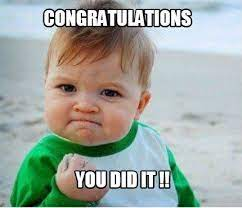

# **FEEDBACK FORM**

https://docs.google.com/forms/d/e/1FAIpQLScnAaAKvph9R3vINyCtOOMiav-tSMsRGlJReMaHyPjsXDlTIA/viewform